# Phyloseq-working

## 10.17.26 | tidy metadata

### Setting up R/phyloseq with conda environment in unity

Add phyloseq to `dada2-env` in terminal
```
conda activate dada2-env
conda install -c bionconda bioconda-phyloseq
```

### Metadata tidying

In [ ]:
# Load packages
suppressPackageStartupMessages({
    library(phyloseq)
    library(tidyverse)
})

In [ ]:
# Read 16S processing tracker csv
meta16S <- read.csv("/project/pi_sarah_gignouxwolfsohn_uml_edu/jade/ORCC_16S/metadata/16S_tracker.csv")
dim(meta16S)
head(meta16S)

In [ ]:
# Tidy data
meta16S <- meta16S %>% 
                mutate(Original_order = NULL) %>%
                # Un-concatenate sample name
                separate(Sample_name,  into = c("Year", "Phase_1_treat", "Phase_2_treat", "Tag"), sep = "_", remove = FALSE) %>%
                # Add tissue type to sample name to match ASV table
                mutate(Sample_name = paste0(Sample_name, sep = "_", Tissue)) %>%
                # Separate the treatment and replicate into two columns
                extract(Phase_1_treat, into = c("Phase_1_treat", "Phase_1_rep"), regex = "([A-Za-z]+)([0-9]+)") %>%
                extract(Phase_2_treat, into = c("Phase_2_treat", "Phase_2_rep"), regex = "([A-Za-z]+)([0-9]+)") %>%
                # Add column for treatment combination
                mutate(Combined_treat = paste0(Phase_1_treat, Phase_2_treat)) %>%
                mutate(Combined_treat = gsub("[^A-Z]", "", Combined_treat)) %>%
                relocate(Combined_treat, .after = Year) %>%
                # Make the treatment replicate an integer rather than a string
                mutate(Phase_1_rep = as.integer(Phase_1_rep)) %>%
                mutate(Phase_2_rep = as.integer(Phase_2_rep)) %>%
                # Rename some columns
                rename(Date = X16S_date) %>%
                rename(Adapters = X16S_adapters) %>%
                # Format dates
                mutate(Date = as.Date(Date, format = "%m/%d/%y")) %>%
                mutate(Index_date = as.Date(Index_date, format = "%m/%d/%y"))
head(meta16S)

In [ ]:
# Check warning message
meta16S[239:247,]
meta16S[280:283,]
# Missing pieces are control samples

In [ ]:
# Remove empty rows 282, 283
meta16S <- meta16S[-282:-283,]
tail(meta16S)

In [ ]:
# Save tided csv
write.csv(meta16S, "/project/pi_sarah_gignouxwolfsohn_uml_edu/jade/ORCC_16S/metadata/metadata_samples.csv", row.names=FALSE)

## 10.18.26 | phyloseq object using decipher taxonomy

In [ ]:
# Load packages
suppressPackageStartupMessages({
    library(phyloseq)
    library(tidyverse)
})

In [ ]:
# Read ASV table
asvTable <- readRDS("/scratch4/workspace/jade_fiorilla_student_uml_edu-rawseqorcc/dada2/ASV_nochim_2.rds")

# Read taxonomy table
taxaDecipher <- readRDS("/scratch4/workspace/jade_fiorilla_student_uml_edu-rawseqorcc/dada2/decipher_taxa_sp.rds")

# Read tidied metadata
sampleMetadata <- read.csv("/project/pi_sarah_gignouxwolfsohn_uml_edu/jade/ORCC_16S/metadata/metadata_samples.csv", row.names=1)

In [ ]:
# Check that row names are identical
head(asvTable)
head(sampleMetadata)

In [ ]:
# Rearrange metadata sample order to match ASV table sample order
sampleMetadata <- sampleMetadata[match(rownames(asvTable), rownames(sampleMetadata)), ]
head(asvTable)
head(sampleMetadata)

In [ ]:
# Create phyloseq object
ps <- phyloseq(otu_table(asvTable, taxa_are_rows = FALSE),
                     sample_data(sampleMetadata),
                     tax_table(taxaDecipher))
ps

In [ ]:
# Extract ASV sequences
dna <- Biostrings::DNAStringSet(taxa_names(ps))
names(dna) <- taxa_names(ps)

# Create reference sequence component of phyloseq object to store the raw ASVs
ps <- merge_phyloseq(ps, dna)

# Rename ASVs numerically
taxa_names(ps) <- paste0("ASV", seq(ntaxa(ps)))
ps

In [ ]:
# Save phyloseq object
saveRDS(ps, "/scratch4/workspace/jade_fiorilla_student_uml_edu-rawseqorcc/dada2/ps.rds")

## 10.20.26 | clean phyloseq object

Continue work with the phyloseq object created 10.18.26 using the decipher taxonomic assignment tool.

### Baseline cleaning and tidying of object

Cleaned and pruned phyloseq object to use going forward will be `ps_norm`

In [38]:
# Load packages
suppressPackageStartupMessages({
    library(phyloseq)
    library(tidyverse)
})

In [26]:
# Read in phyloseq object
ps <- readRDS("/scratch4/workspace/jade_fiorilla_student_uml_edu-rawseqorcc/dada2/ps.rds")

In [27]:
# Remove samples with less than 10k reads
ps_10k <- prune_samples(sample_sums(ps) >= 10000, ps)

# Compare phyloseq objects
ps
ps_10k

phyloseq-class experiment-level object
otu_table()   OTU Table:         [ 145375 taxa and 281 samples ]
sample_data() Sample Data:       [ 281 samples by 35 sample variables ]
tax_table()   Taxonomy Table:    [ 145375 taxa by 7 taxonomic ranks ]
refseq()      DNAStringSet:      [ 145375 reference sequences ]

phyloseq-class experiment-level object
otu_table()   OTU Table:         [ 145375 taxa and 274 samples ]
sample_data() Sample Data:       [ 274 samples by 35 sample variables ]
tax_table()   Taxonomy Table:    [ 145375 taxa by 7 taxonomic ranks ]
refseq()      DNAStringSet:      [ 145375 reference sequences ]

In [28]:
# Explore which samples were lost
low_samples <- sample_sums(ps) < 10000
sample_names(ps)[low_samples]

[1] "2024_Both01_Null_O03_gill"   "2024_Both04_Null_O32_gill"  
[3] "2024_Both05_Both06_O69_gill" "2024_Cont03_Null_W21_gill"  
[5] "2024_Cont04_Cont06_W67_gill" "2024_Warm01_Hyp05_G49_gill" 
[7] "Pooled_negative_rack3_2_NA"

**Samples removed due to <10,000 reads**  
Phase 1 - B1O3_gill, B4O32_gill, C3W21_gill  
Phase 2 - B5B6O69_gill, C4C6W67_gill, W1J5G49_gill  
Negative - Pooled negative rack 3_2

In [29]:
# Keep just bacteria
ps_bacteria <- subset_taxa(ps_10k, domain == "Bacteria")
ps_bacteria

phyloseq-class experiment-level object
otu_table()   OTU Table:         [ 66795 taxa and 274 samples ]
sample_data() Sample Data:       [ 274 samples by 35 sample variables ]
tax_table()   Taxonomy Table:    [ 66795 taxa by 7 taxonomic ranks ]
refseq()      DNAStringSet:      [ 66795 reference sequences ]

In [31]:
# Remove taxa that are no longer represented in phyloseq object
ps_prune <- prune_taxa(taxa_sums(ps_bacteria) > 0, ps_bacteria)
ps_prune

phyloseq-class experiment-level object
otu_table()   OTU Table:         [ 66218 taxa and 274 samples ]
sample_data() Sample Data:       [ 274 samples by 35 sample variables ]
tax_table()   Taxonomy Table:    [ 66218 taxa by 7 taxonomic ranks ]
refseq()      DNAStringSet:      [ 66218 reference sequences ]

In [34]:
# Convert raw counts to relative abundance counts per million
ps_norm = transform_sample_counts(ps_prune, function(x) 1E6 * x / sum(x))

In [33]:
# Save phyloseq object
saveRDS(ps, "/scratch4/workspace/jade_fiorilla_student_uml_edu-rawseqorcc/dada2/ps_norm.rds")

## 10.26.26 | explore the data!

In [1]:
# Load packages
suppressPackageStartupMessages({
    library(phyloseq)
    library(tidyverse)
    library(data.table)
})
    
options(repr.plot.width=20, repr.plot.height=15)

### Looking at raw data pre-cleaning

In [2]:
ps <- readRDS("/scratch4/workspace/jade_fiorilla_student_uml_edu-rawseqorcc/dada2/ps.rds")

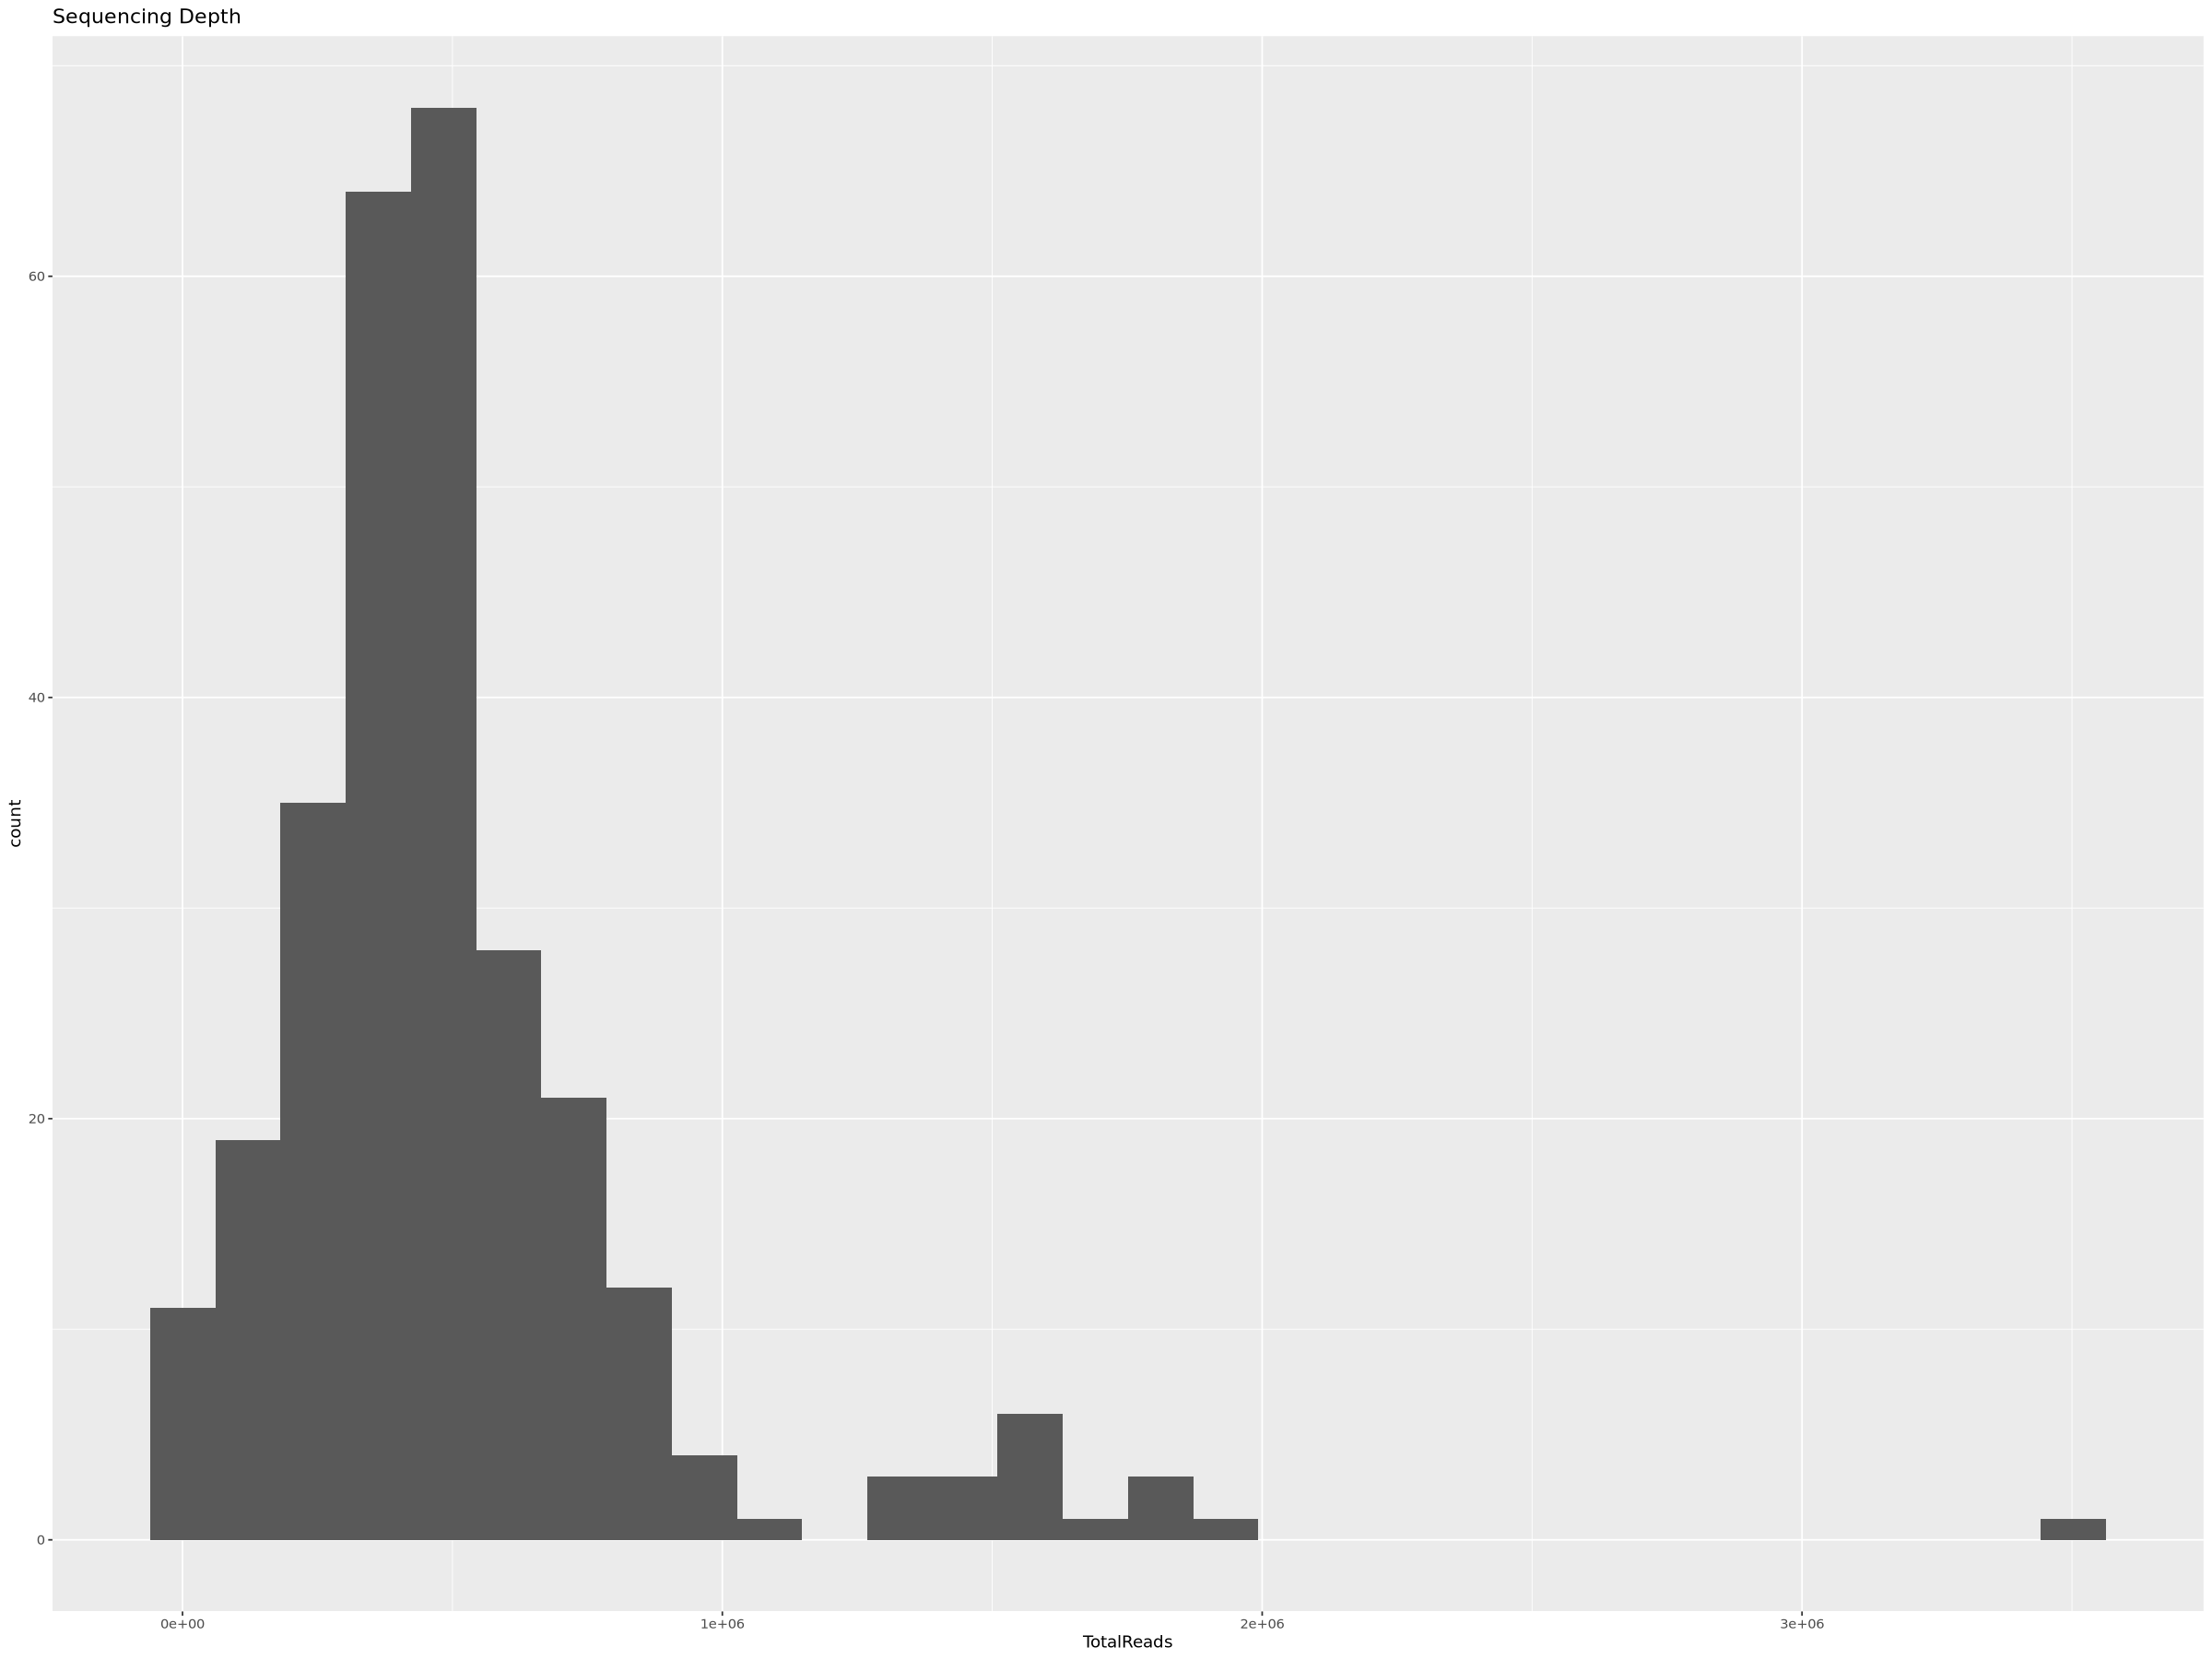

In [15]:
# Check read count of all samples
readcount = data.table(as(sample_data(ps), "data.frame"),
                 TotalReads = sample_sums(ps), 
                 keep.rownames = TRUE)
ggplot(readcount, aes(TotalReads)) + 
    geom_histogram(bins = 30) + 
    ggtitle("Sequencing Depth")

- How many reads do the negatives have and what are they?
    - Should I filter these out of the other samples? 
- What sample has so many reads?
- We know some 7 samples have < 10,000 reads but what reads do they have?

### Examining negatives

In [3]:
# Subset ps to only include negatives
ps_neg <- prune_samples(
  grepl("negative", sample_names(ps), ignore.case = TRUE), ps)
ps_neg

phyloseq-class experiment-level object
otu_table()   OTU Table:         [ 145375 taxa and 6 samples ]
sample_data() Sample Data:       [ 6 samples by 35 sample variables ]
tax_table()   Taxonomy Table:    [ 145375 taxa by 7 taxonomic ranks ]
refseq()      DNAStringSet:      [ 145375 reference sequences ]

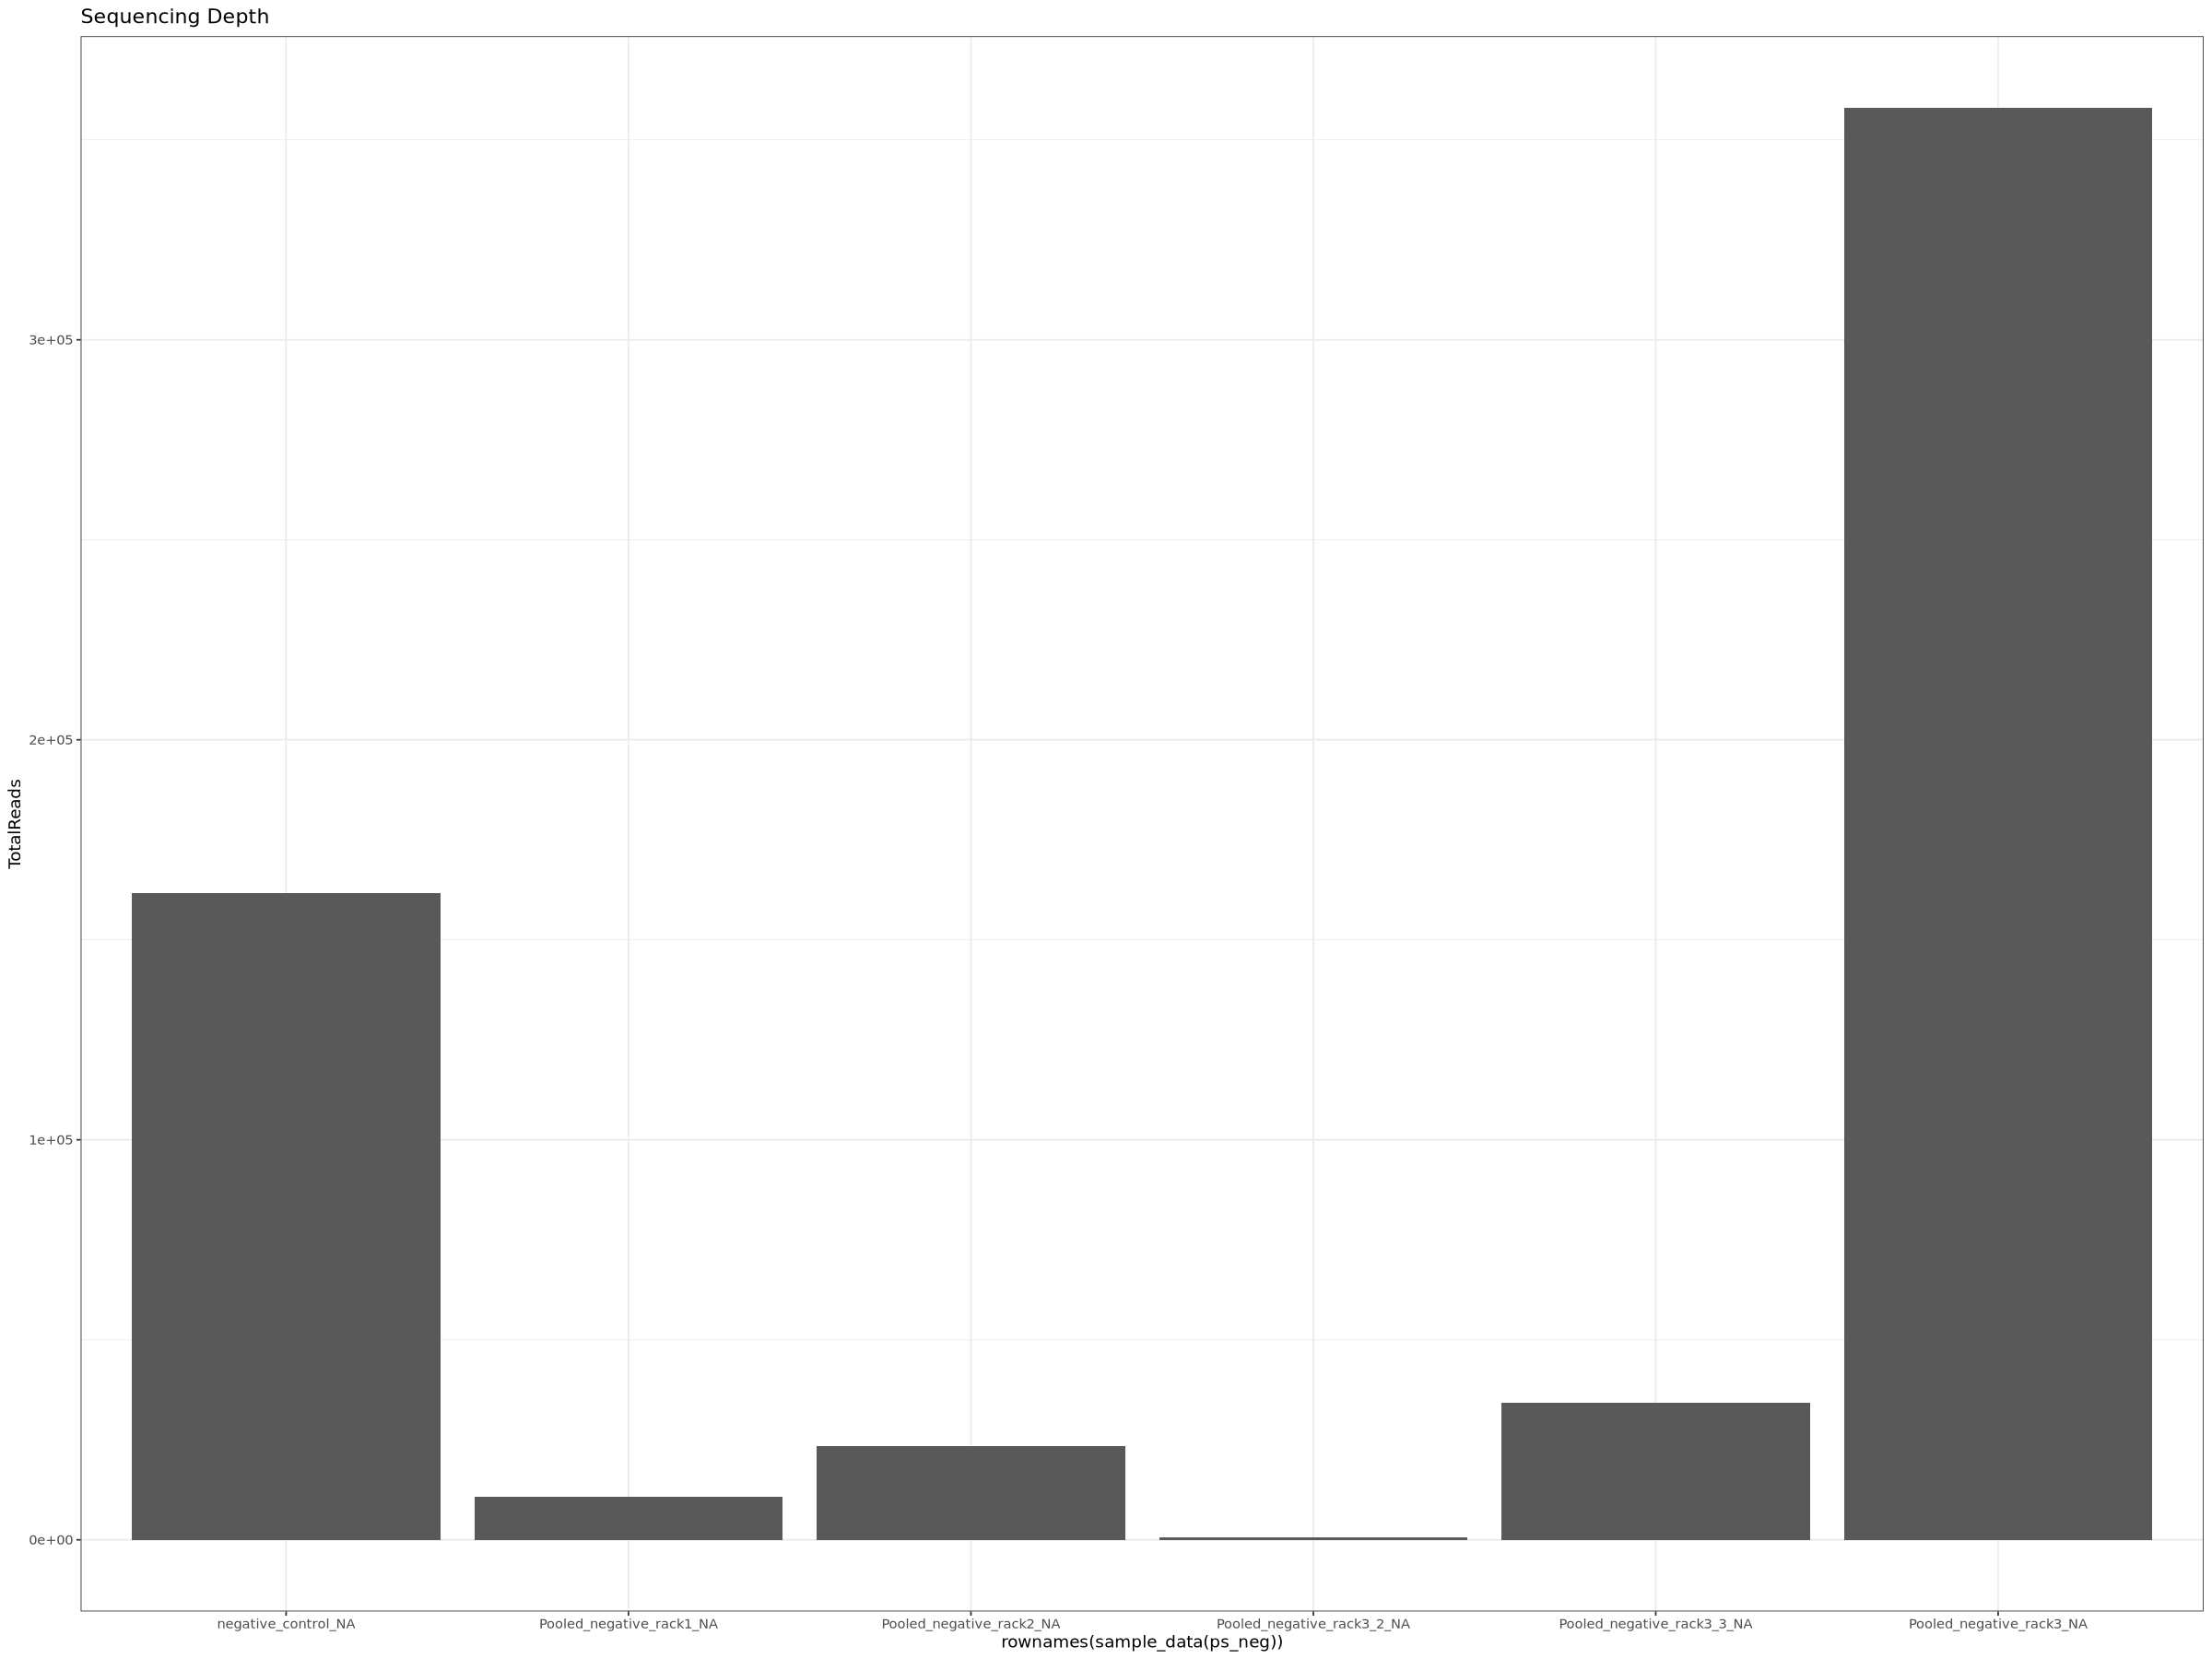

In [57]:
# Check read counts of negatives
readcount_neg <- data.table(as(sample_data(ps_neg), "data.frame"),
                 TotalReads = sample_sums(ps_neg), 
                 keep.rownames = TRUE)
ggplot(readcount_neg, aes(x = rownames(sample_data(ps_neg)), y = TotalReads)) + 
    geom_col() + 
    ggtitle("Sequencing Depth") +
    theme_bw()

In [9]:
# PCoA ordination of negative controls
neg.ord <- ordinate(ps_neg, "PCoA", "bray")

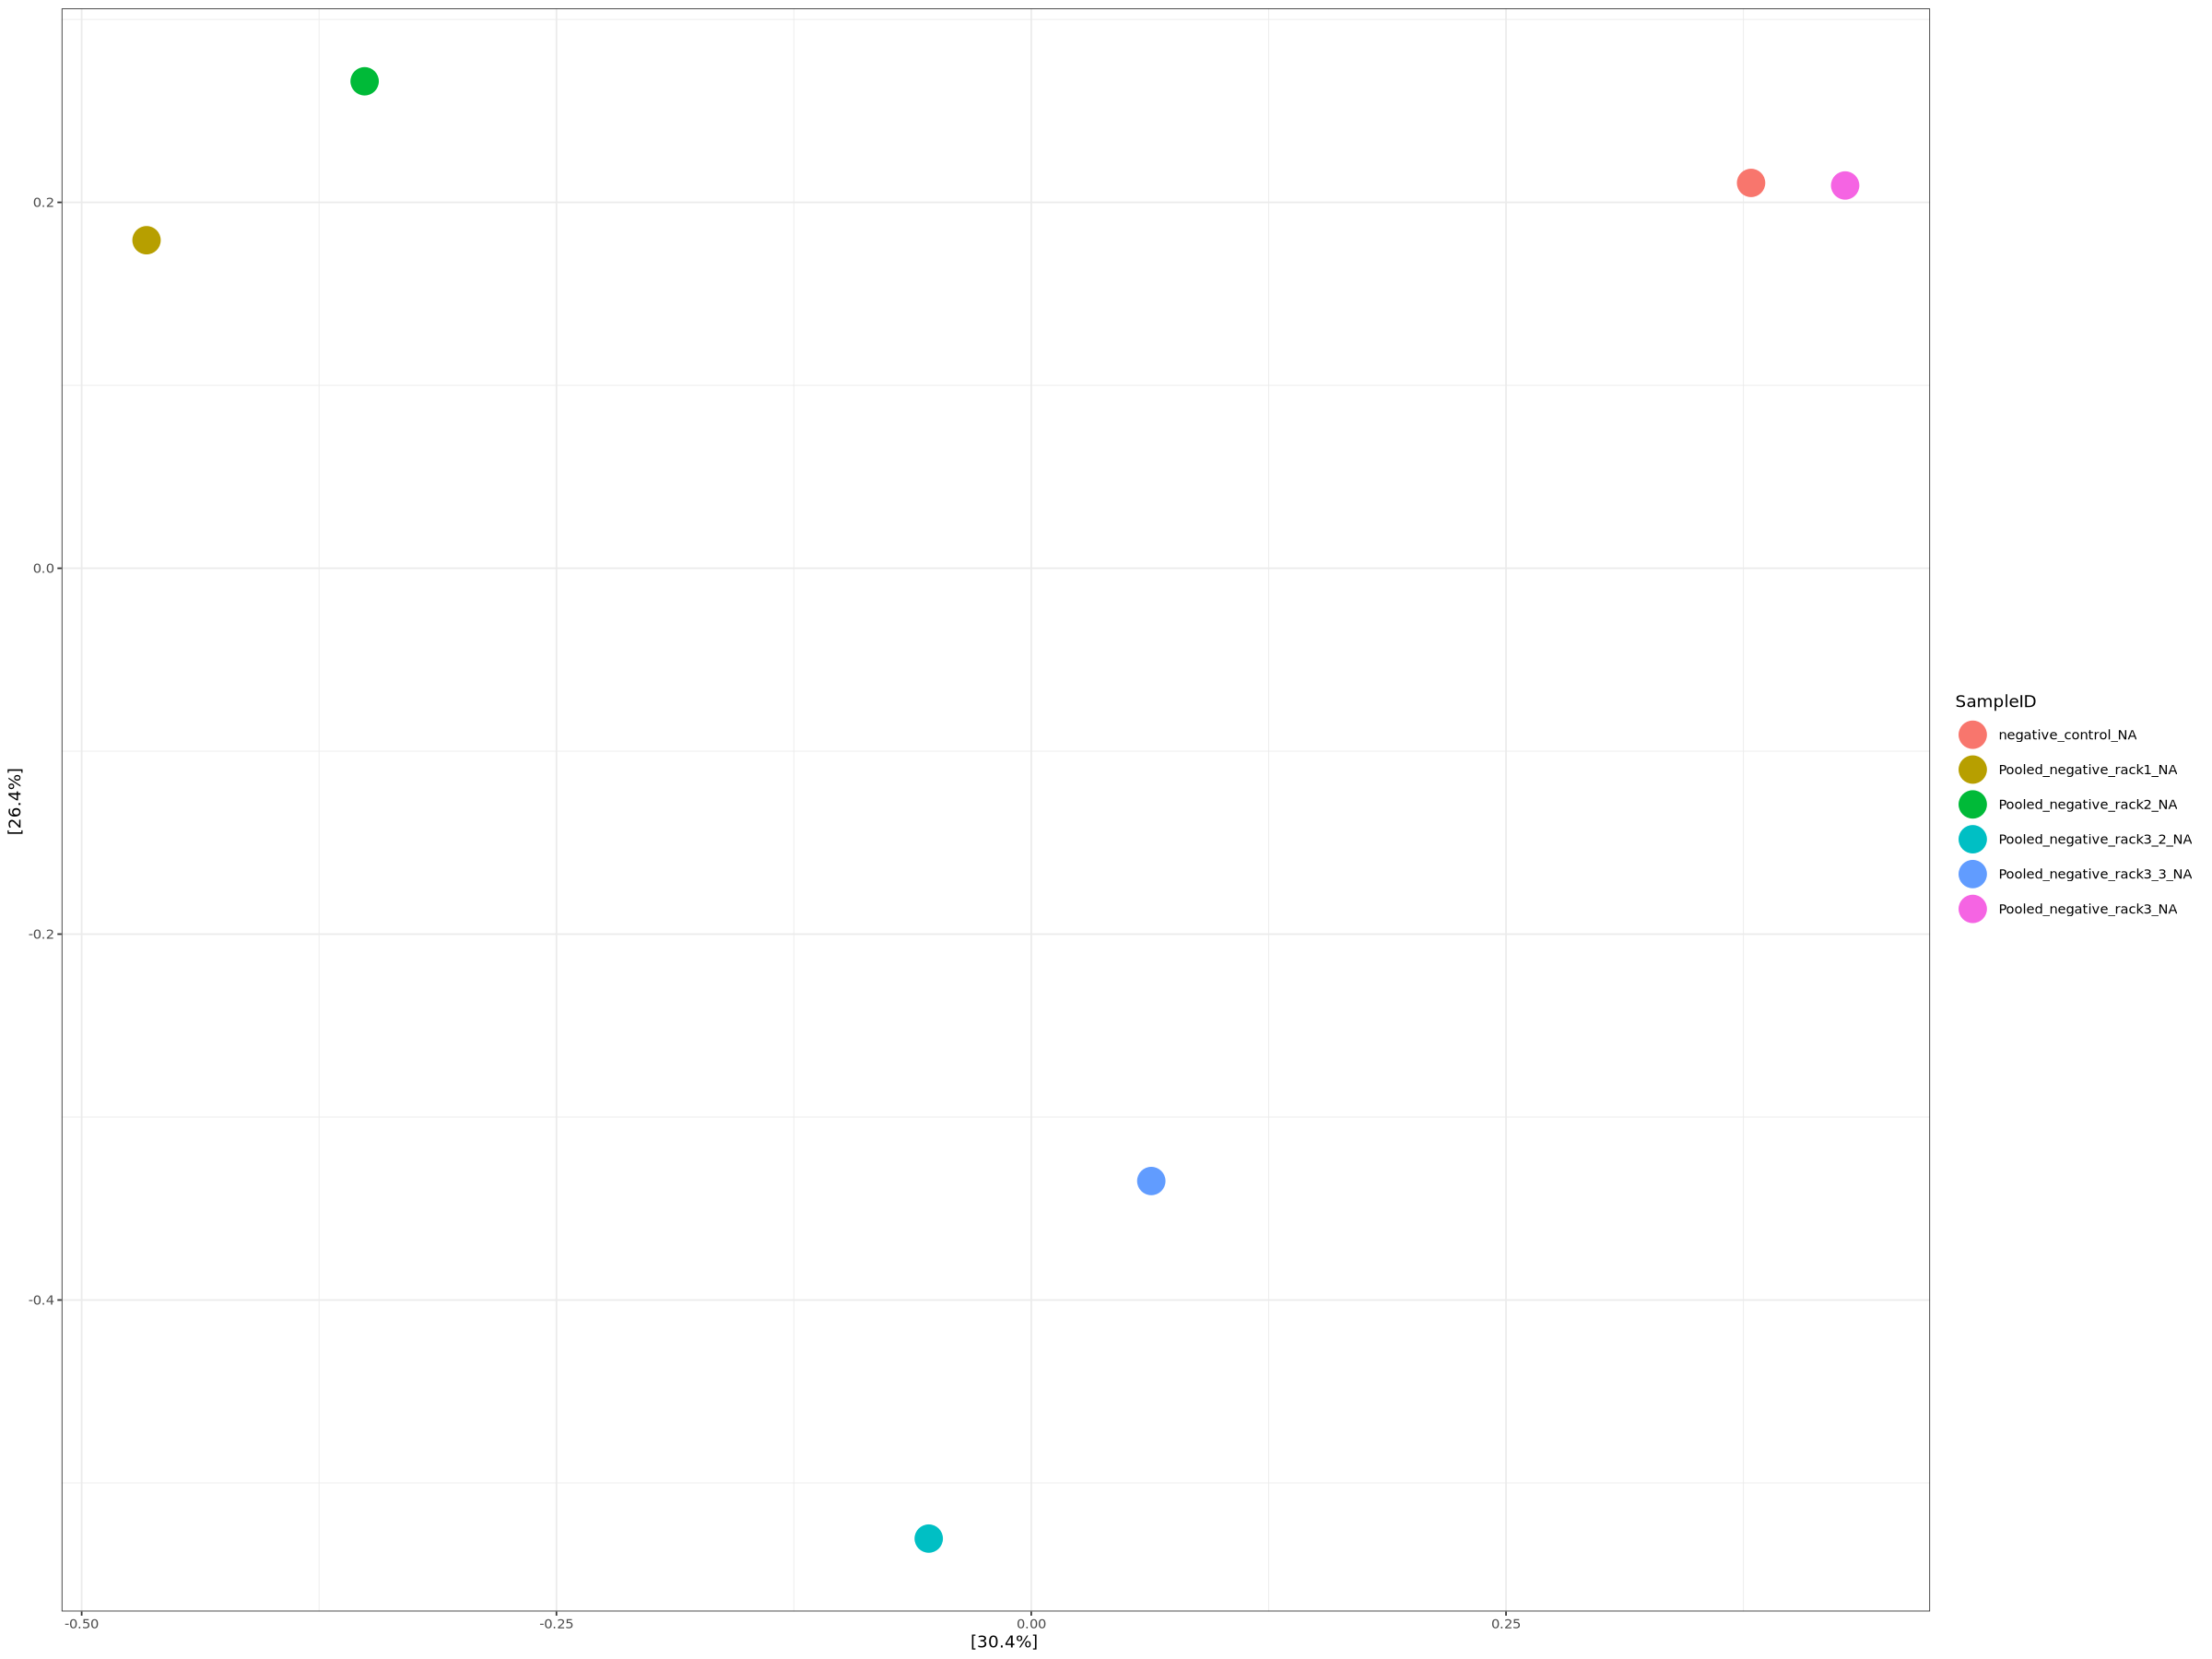

In [10]:
# Plot PCoA but convert row names to column first
sample_data(ps_neg)$SampleID <- rownames(sample_data(ps_neg))
plot_ordination(ps_neg, neg.ord, color = "SampleID") +
    geom_point(size=8) +
    theme_bw()